<a href="https://colab.research.google.com/github/primrosemandy93-maker/Datheon_Machine_Learning_-_Data_Science_Internship/blob/main/task_1_iris/Task_1_Iris_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

In [3]:
# Load the Iris flower dataset.
iris = load_iris(as_frame=True)

# X contains the flower measurements.
X = iris.data

# y contains the flower species as numbers: 0, 1, or 2.
y = iris.target

# Create a table with readable species names.
df = X.copy()
df["species"] = y.map(dict(enumerate(iris.target_names)))

display(df.head())

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isna().sum())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Dataset shape: (150, 5)

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


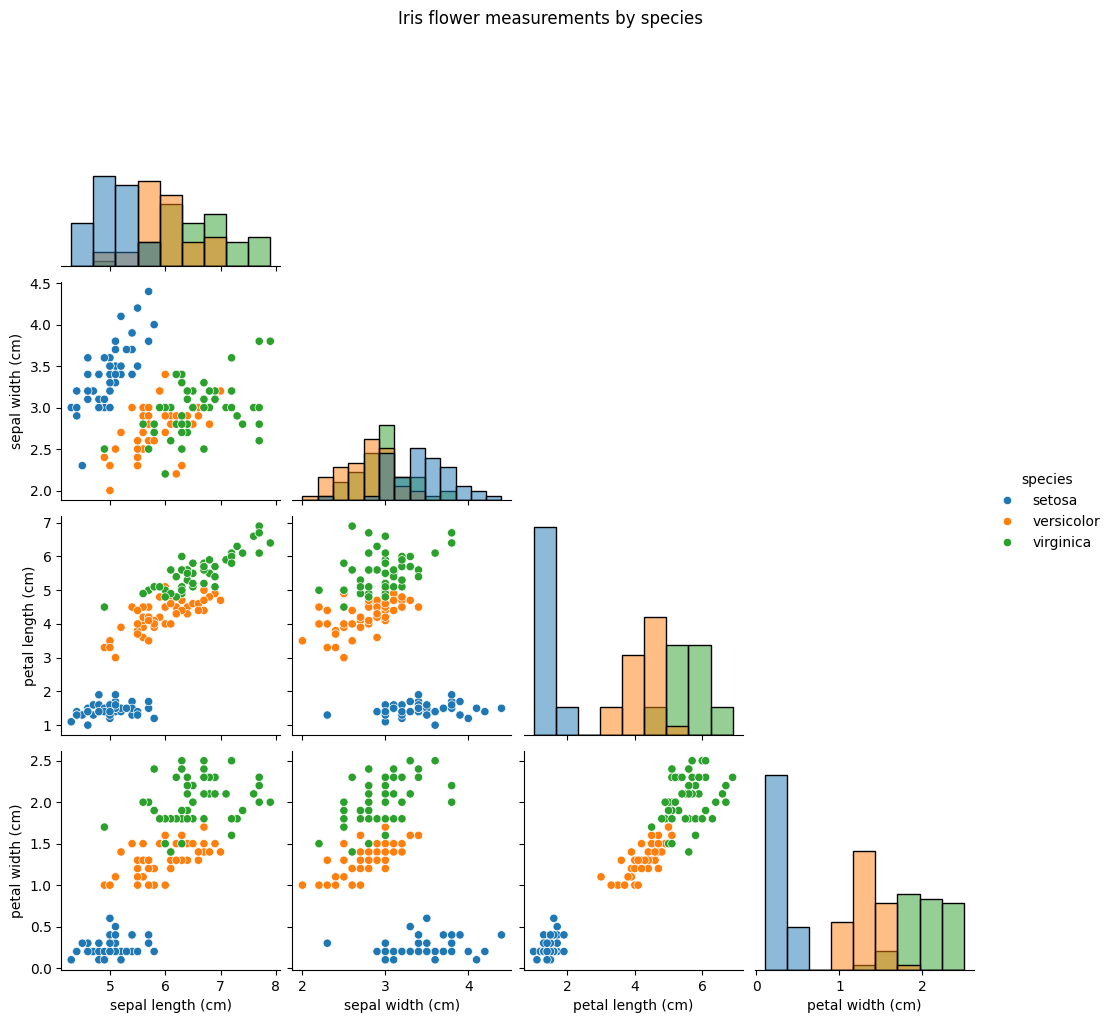

In [4]:
# Compare flower measurements across the three species.
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist",
    corner=True,
)

plt.suptitle("Iris flower measurements by species", y=1.02)
plt.show()

In [6]:
# Use 80% of the flowers for training and 20% for testing.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Training flowers:", len(X_train))
print("Testing flowers:", len(X_test))

Training flowers: 120
Testing flowers: 30


In [8]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42,
        )),
    ]),
    "Decision Tree": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", DecisionTreeClassifier(
            max_depth=3,
            random_state=42,
        )),
    ]),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name}: training complete")

Logistic Regression: training complete
Decision Tree: training complete


In [9]:
results = []

for name, model in models.items():
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
    })

    print(f"\n{name}")
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1, 2],
        target_names=iris.target_names,
        zero_division=0,
    ))

results_df = pd.DataFrame(results)
display(results_df.round(3))


Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.933,0.933,0.933,0.933
1,Decision Tree,0.967,0.970,0.967,0.967


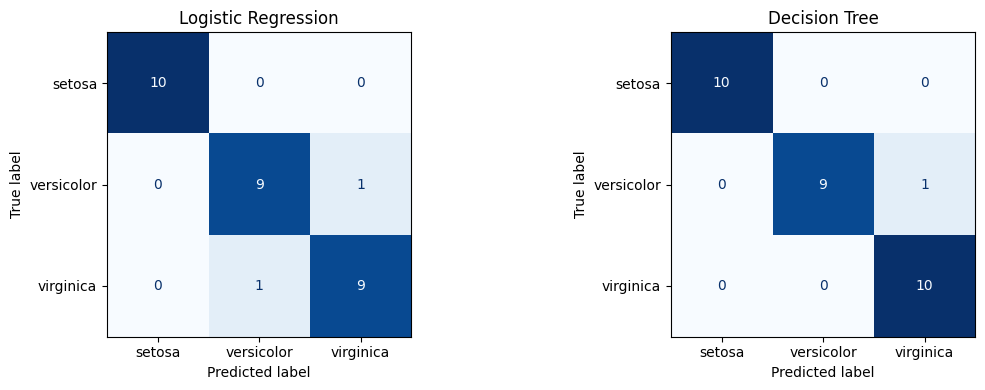

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=iris.target_names,
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

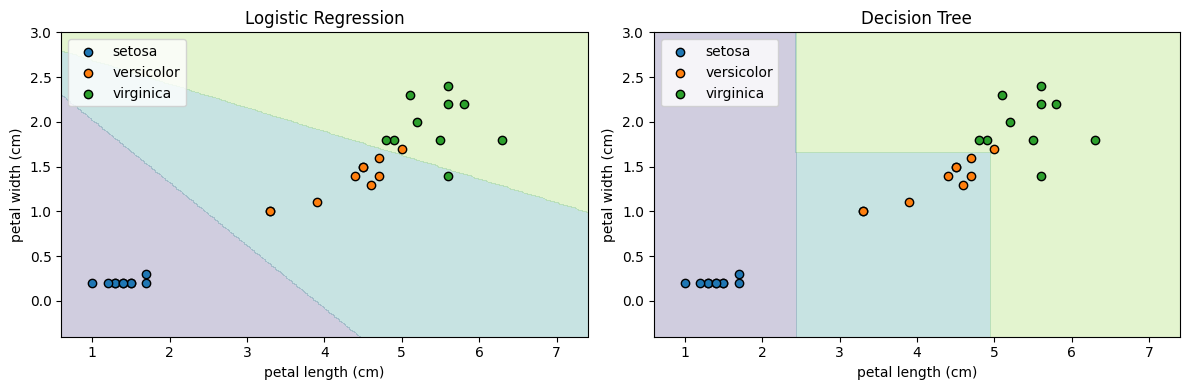

In [11]:
# Use two measurements so we can draw a flat graph.
features = ["petal length (cm)", "petal width (cm)"]

X_train_2d = X_train[features]
X_test_2d = X_test[features]

# Create a grid covering the training measurements.
x_min, x_max = X_train_2d.iloc[:, 0].min() - 0.5, X_train_2d.iloc[:, 0].max() + 0.5
y_min, y_max = X_train_2d.iloc[:, 1].min() - 0.5, X_train_2d.iloc[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250),
)

grid = pd.DataFrame(
    np.c_[xx.ravel(), yy.ravel()],
    columns=features,
)

visual_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=3, random_state=42
    ),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, classifier) in zip(axes, visual_models.items()):
    model_2d = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", classifier),
    ])

    model_2d.fit(X_train_2d, y_train)
    predictions = model_2d.predict(grid).reshape(xx.shape)

    ax.contourf(
        xx, yy, predictions,
        levels=[-0.5, 0.5, 1.5, 2.5],
        cmap="viridis",
        alpha=0.25,
    )

    for label, species in enumerate(iris.target_names):
        mask = y_test == label

        ax.scatter(
            X_test_2d.loc[mask, features[0]],
            X_test_2d.loc[mask, features[1]],
            label=species,
            edgecolors="black",
        )

    ax.set_xlabel(features[0])
    ax.set_ylabel(features[1])
    ax.set_title(name)
    ax.legend()

plt.tight_layout()
plt.show()

In [13]:
print(results_df.round(3).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-score
Logistic Regression     0.933      0.933   0.933     0.933
      Decision Tree     0.967      0.970   0.967     0.967


## Results and Conclusion

Both models were trained on 120 Iris flowers and evaluated on 30
unseen flowers using an 80/20 stratified split.

| Model | Accuracy | Macro Precision | Macro Recall | Macro F1 |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.933 | 0.933 | 0.933 | 0.933 |
| Decision Tree | 0.967 | 0.970 | 0.967 | 0.967 |

The Decision Tree achieved the higher test accuracy, correctly
classifying 29 out of 30 flowers. Logistic Regression correctly
classified 28 out of 30 flowers.

Feature scaling was fitted within each pipeline using only the
training data to prevent data leakage.

The decision boundary plots used separate models trained on two
petal measurements for visualization. The evaluation table above
uses models trained on all four measurements.

These results come from one small test set. A difference of one
correct prediction does not establish that the Decision Tree will
always perform better. Stratified cross validation would provide
a more reliable comparison.